In [16]:
%pip install nltk beautifulsoup4 requests

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
import requests
import re
import nltk
from bs4 import BeautifulSoup
from collections import Counter
import operator

# Download the NLTK stop-word list.
# You only need to do this the first time.
nltk.download('stopwords')

# Common English words that we don't want to include
# in our word-frequency analysis.
stop_words = nltk.corpus.stopwords.words('english')

# Additional words/symbols to ignore.
stop_words += [
    'ut',
    "'re",
    "'s"
]

%matplotlib inline

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [34]:
def cleanHtml(html):
    soup = BeautifulSoup(html, 'html.parser')
    return soup.get_text()

In [35]:
# Character names to remove from the word-frequency analysis

shakespeare_names = {
    # Hamlet
    'hamlet',
    'horatio',
    'polonius',
    'ophelia',
    'claudius',
    'gertrude',
    'laertes',
    'fortinbras',
    'rosencrantz',
    'guildenstern',
    'osric',
    'marcellus',
    'bernardo',
    'francisco',

    # Romeo and Juliet
    'romeo',
    'juliet',
    'mercutio',
    'benvolio',
    'tybalt',
    'friar',
    'lawrence',
    'paris',
    'capulet',
    'montague',
    'nurse',
    'prince',
    'lady',
    'servant',
    'apothecary'
}

# Common words that appear in stage directions
stage_direction_words = {
    'enter',
    'exit',
    'exeunt',
    're-enter',
    'aside',
    'within',
    'above',
    'below',
    'alarum',
    'flourish',
    'noise',
    'music',
    'sings',
    'dies',
    'falls',
    'kneels',
    'draws',
    'sheathes',
    'fighting',
    'fights',
    'opens',
    'closes'
}

In [36]:
def cleanWord(w):
    # Remove punctuation and special characters.
    w = re.sub(r'[^\w\s\'-]', '', w)

    # Remove words that consist entirely of numbers.
    if re.fullmatch(r'[0-9]+', w):
        return ""

    return w

In [37]:
def get_wf(URL):

    # Get the web page containing the work.
    r = requests.get(URL)

    # Make sure the request was successful.
    r.raise_for_status()

    # Remove HTML markup and convert everything to lowercase.
    t = cleanHtml(r.text).lower()

    # Split the text into individual words.
    wds = re.split(r'\s+', t)

    # Clean each word.
    cleaned_words = []

    for w in wds:
        w = cleanWord(w)

        if w == "":
            continue

        # Remove character names and stage-direction words
        if w in shakespeare_names:
            continue

        if w in stage_direction_words:
            continue

        cleaned_words.append(w)

    # Count how many times each word occurs.
    wf = Counter(cleaned_words)

    # Remove stop words.
    for k in stop_words:
        wf.pop(k, None)

    # Calculate the total number of non-stop words.
    tw = sum(wf.values())

    # Sort words from most frequent to least frequent.
    wfs = sorted(
        wf.items(),
        key=operator.itemgetter(1),
        reverse=True
    )

    # Keep only the 15 most frequent words.
    ml = min(len(wfs), 15)

    return wfs[0:ml], tw

In [38]:
(wf_hamlet, tw_hamlet) = get_wf(
    'https://www.gutenberg.org/files/1524/1524-0.txt'
)

print("Hamlet")
print("Total non-stop words:", tw_hamlet)
print()
print("Top 15 words:")

for word, frequency in wf_hamlet:
    print(word, frequency)

Hamlet
Total non-stop words: 15347

Top 15 words:
lord 222
king 193
queen 118
shall 114
good 107
come 105
thou 104
let 94
well 89
thy 86
would 81
like 80
know 75
sir 75
tis 74


In [39]:
(wf_romeo, tw_romeo) = get_wf(
    'https://www.gutenberg.org/files/1112/1112-0.txt'
)

print("Romeo and Juliet")
print("Total non-stop words:", tw_romeo)
print()
print("Top 15 words:")

for word, frequency in wf_romeo:
    print(word, frequency)

Romeo and Juliet
Total non-stop words: 13912

Top 15 words:
thou 277
thy 178
rom 149
thee 138
loue 135
haue 126
shall 106
come 100
iul 97
man 84
nur 77
night 73
ile 72
death 69
good 68


In [40]:
def normalize_frequency(wf, total_words):

    normalized = []

    for word, frequency in wf:
        rate = (frequency / total_words) * 1000
        normalized.append((word, rate))

    return normalized


normalized_hamlet = normalize_frequency(
    wf_hamlet,
    tw_hamlet
)

normalized_romeo = normalize_frequency(
    wf_romeo,
    tw_romeo
)

In [41]:
print("Hamlet")
print("Frequency per 1,000 words")
print("--------------------------------")

for word, frequency in normalized_hamlet:
    print(f"{word}: {frequency:.2f}")


print()
print("Romeo and Juliet")
print("Frequency per 1,000 words")
print("--------------------------------")

for word, frequency in normalized_romeo:
    print(f"{word}: {frequency:.2f}")

Hamlet
Frequency per 1,000 words
--------------------------------
lord: 14.47
king: 12.58
queen: 7.69
shall: 7.43
good: 6.97
come: 6.84
thou: 6.78
let: 6.12
well: 5.80
thy: 5.60
would: 5.28
like: 5.21
know: 4.89
sir: 4.89
tis: 4.82

Romeo and Juliet
Frequency per 1,000 words
--------------------------------
thou: 19.91
thy: 12.79
rom: 10.71
thee: 9.92
loue: 9.70
haue: 9.06
shall: 7.62
come: 7.19
iul: 6.97
man: 6.04
nur: 5.53
night: 5.25
ile: 5.18
death: 4.96
good: 4.89


In [42]:
import numpy as np
import matplotlib.pyplot as plt


def plotTwoLists(wf_hamlet, wf_romeo, title):

    # Create the figure.
    f = plt.figure(figsize=(12, 7))

    # Overall title.
    f.suptitle(title, fontsize=20)

    # -------------------------------------------------
    # Hamlet
    # -------------------------------------------------

    ax1 = f.add_subplot(121)

    ax1.tick_params(
        axis='both',
        which='major',
        labelsize=12
    )

    # Reverse the list so the most frequent word
    # appears at the top of the graph.
    hamlet_plot = wf_hamlet[::-1]

    ax1.set_yticks(
        np.arange(len(hamlet_plot))
    )

    ax1.set_yticklabels(
        [x[0] for x in hamlet_plot]
    )

    ax1.barh(
        range(len(hamlet_plot)),
        [x[1] for x in hamlet_plot],
        align='center'
    )

    ax1.set_title("Hamlet")
    ax1.set_xlabel("Occurrences per 1,000 words")


    # -------------------------------------------------
    # Romeo and Juliet
    # -------------------------------------------------

    ax2 = f.add_subplot(122)

    ax2.tick_params(
        axis='both',
        which='major',
        labelsize=12
    )

    # Reverse the list so the most frequent word
    # appears at the top of the graph.
    romeo_plot = wf_romeo[::-1]

    ax2.set_yticks(
        np.arange(len(romeo_plot))
    )

    ax2.set_yticklabels(
        [x[0] for x in romeo_plot]
    )

    ax2.barh(
        range(len(romeo_plot)),
        [x[1] for x in romeo_plot],
        align='center'
    )

    ax2.set_title("Romeo and Juliet")
    ax2.set_xlabel("Occurrences per 1,000 words")


    # Adjust the spacing between the two plots.
    plt.subplots_adjust(wspace=0.5)

    plt.savefig("hamlet_vs_romeo.png", dpi=300, bbox_inches="tight")

    # Display the graph.
    plt.show()

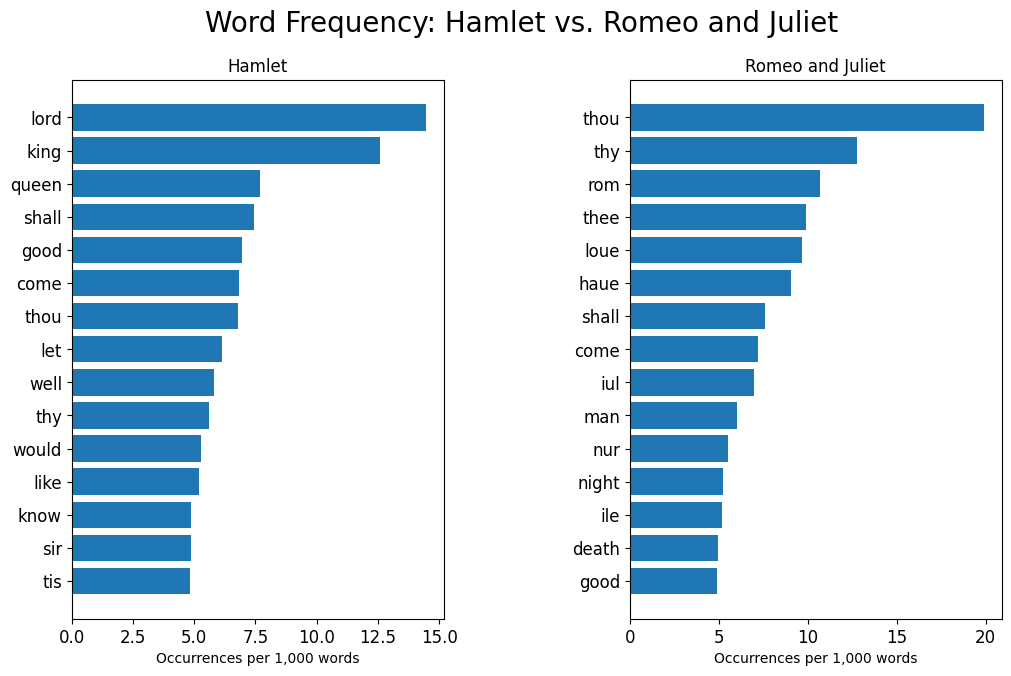

In [43]:
plotTwoLists(
    normalized_hamlet,
    normalized_romeo,
    'Word Frequency: Hamlet vs. Romeo and Juliet'
)

In [44]:
# Analyze Edgar Allan Poe's "The Tell-Tale Heart"

(wf_poe, tw_poe) = get_wf(
    'https://www.gutenberg.org/files/2148/2148-0.txt'
)

print("The Tell-Tale Heart - Edgar Allan Poe")
print("Total non-stop words:", tw_poe)
print()
print("Top 15 words:")

for word, frequency in wf_poe:
    print(word, frequency)

The Tell-Tale Heart - Edgar Allan Poe
Total non-stop words: 45339

Top 15 words:
upon 506
one 275
could 216
said 180
would 178
even 142
yet 130
long 125
thus 122
made 118
first 112
man 110
length 106
us 103
still 103


In [45]:
# Normalize the word frequencies so the two works can be compared fairly.

normalized_hamlet = normalize_frequency(
    wf_hamlet,
    tw_hamlet
)

normalized_poe = normalize_frequency(
    wf_poe,
    tw_poe
)

In [46]:
print("Hamlet - William Shakespeare")
print("Frequency per 1,000 words")
print("--------------------------------")

for word, frequency in normalized_hamlet:
    print(f"{word}: {frequency:.2f}")


print()
print("The Tell-Tale Heart - Edgar Allan Poe")
print("Frequency per 1,000 words")
print("--------------------------------")

for word, frequency in normalized_poe:
    print(f"{word}: {frequency:.2f}")

Hamlet - William Shakespeare
Frequency per 1,000 words
--------------------------------
lord: 14.47
king: 12.58
queen: 7.69
shall: 7.43
good: 6.97
come: 6.84
thou: 6.78
let: 6.12
well: 5.80
thy: 5.60
would: 5.28
like: 5.21
know: 4.89
sir: 4.89
tis: 4.82

The Tell-Tale Heart - Edgar Allan Poe
Frequency per 1,000 words
--------------------------------
upon: 11.16
one: 6.07
could: 4.76
said: 3.97
would: 3.93
even: 3.13
yet: 2.87
long: 2.76
thus: 2.69
made: 2.60
first: 2.47
man: 2.43
length: 2.34
us: 2.27
still: 2.27


In [47]:
def plot_hamlet_vs_poe(wf_hamlet, wf_poe, title):

    f = plt.figure(figsize=(12, 7))
    f.suptitle(title, fontsize=20)

    ax1 = f.add_subplot(121)
    ax1.tick_params(
        axis='both',
        which='major',
        labelsize=12
    )

    hamlet_plot = wf_hamlet[::-1]

    ax1.set_yticks(
        np.arange(len(hamlet_plot))
    )

    ax1.set_yticklabels(
        [x[0] for x in hamlet_plot]
    )

    ax1.barh(
        range(len(hamlet_plot)),
        [x[1] for x in hamlet_plot],
        align='center'
    )

    ax1.set_title("Hamlet - Shakespeare")
    ax1.set_xlabel("Occurrences per 1,000 words")

    ax2 = f.add_subplot(122)
    ax2.tick_params(
        axis='both',
        which='major',
        labelsize=12
    )

    poe_plot = wf_poe[::-1]

    ax2.set_yticks(
        np.arange(len(poe_plot))
    )

    ax2.set_yticklabels(
        [x[0] for x in poe_plot]
    )

    ax2.barh(
        range(len(poe_plot)),
        [x[1] for x in poe_plot],
        align='center'
    )

    ax2.set_title("The Tell-Tale Heart - Poe")
    ax2.set_xlabel("Occurrences per 1,000 words")

    plt.subplots_adjust(wspace=0.5)
    plt.show()

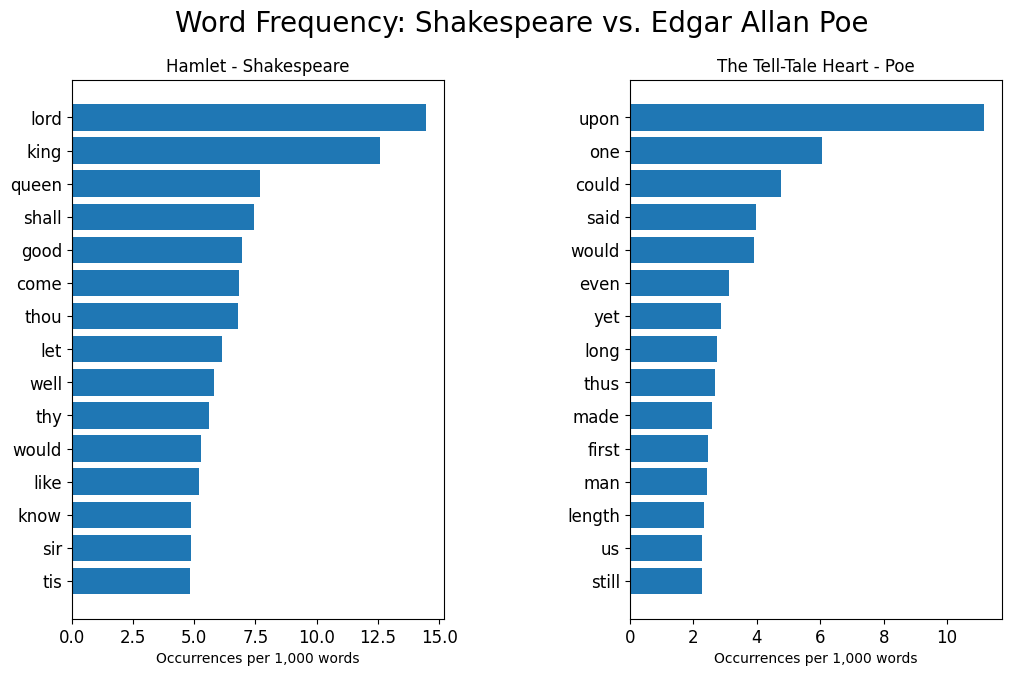

In [48]:
plot_hamlet_vs_poe(
    normalized_hamlet,
    normalized_poe,
    'Word Frequency: Shakespeare vs. Edgar Allan Poe'
)